In [1]:
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import time

In [2]:
class Landscape():

    def __init__(self, N, K, K_within, K_between):
        self.N = N
        self.K = K
        self.K_within = K_within
        self.K_between = K_between
        self.IM, self.IM_dic = None, None
        self.FC = None
        self.cache = {}  # the hashed dict has a higher indexing speed, which helps improve the running speed
        self.cog_cache = {}

    def create_influence_matrix(self):
        IM = np.eye(self.N)
        if self.K_within is None:
            for i in range(self.N):
                probs = [1 / (self.N - 1)] * i + [0] + [1 / (self.N - 1)] * (self.N - 1 - i)
                ids = np.random.choice(self.N, self.K, p=probs, replace=False)
                for index in ids:
                    IM[i][index] = 1
        else:
            for i in range(self.N):
                if i // (self.N // 2) < 1:
                    within = [j for j in range(self.N // 2)]
                    between = [j for j in range(self.N // 2, self.N)]
                    probs = [1 / (self.N // 2 - 1)] * i + [0] + [1 / (self.N // 2 - 1)] * (self.N // 2 - 1 - i)
                    ids_within = np.random.choice(within, self.K_within, p=probs, replace=False)
                    ids_between = np.random.choice(between, self.K_between, replace=False)
                    for index in ids_within:
                        IM[i][index] = 1
                    for index in ids_between:
                        IM[i][index] = 1

                else:
                    within = [j for j in range(self.N // 2, self.N)]
                    between = [j for j in range(self.N // 2)]
                    probs = [1 / (self.N // 2 - 1)] * (i - self.N // 2) + [0] + [1 / (self.N // 2 - 1)] * (
                                self.N - 1 - i)
                    ids_between = np.random.choice(between, self.K_between, replace=False)
                    ids_within = np.random.choice(within, self.K_within, p=probs, replace=False)
                    for index in ids_within:
                        IM[i][index] = 1
                    for index in ids_between:
                        IM[i][index] = 1

        IM_dic = defaultdict(list)
        for i in range(len(IM)):
            for j in range(len(IM[0])):
                if i == j or IM[i][j] == 0:
                    continue
                else:
                    IM_dic[i].append(j)
        self.IM, self.IM_dic = IM, IM_dic

    def create_fitness_config(self,):
        FC = defaultdict(dict)
        for row in range(len(self.IM)):

            k = int(sum(self.IM[row]))
            for i in range(pow(2, k)):
                FC[row][i] = np.random.uniform(0, 1)
        self.FC = FC


    def calculate_fitness(self, state):
        res = 0.0
        for i in range(len(state)):
            dependency = self.IM_dic[i]
            bin_index = "".join([str(state[j]) for j in dependency])
            if state[i] == 0:
                bin_index = "0" + bin_index
            else:
                bin_index = "1" + bin_index
            index = int(bin_index, 2)
            res += self.FC[i][index]
        return res / len(state)

    def store_cache(self,):
        for i in range(pow(2,self.N)):
            bit = bin(i)[2:]
            if len(bit)<self.N:
                bit = "0"*(self.N-len(bit))+bit
            state = [int(cur) for cur in bit]
            self.cache[bit] = self.calculate_fitness(state)


    def initialize(self, first_time=True, norm=True):
        if first_time:
            self.create_influence_matrix()
        self.create_fitness_config()
        self.store_cache()

        # normalization
        if norm:
            normalizor = max(self.cache.values())
            min_normalizor = min(self.cache.values())

            for k in self.cache.keys():
                self.cache[k] = (self.cache[k]-min_normalizor)/(normalizor-min_normalizor)
        self.cog_cache = {}

    def query_fitness(self, state):
        bit = "".join([str(state[i]) for i in range(len(state))])
        return self.cache[bit]

    def query_cog_fitness(self, state, knowledge_sapce):
        remainder = [cur for cur in range(self.N) if cur not in knowledge_sapce]
        regular_expression = "".join(str(state[i]) if i in knowledge_sapce else "*" for i in range(len(state)))
        if regular_expression in self.cog_cache:
            return self.cog_cache[regular_expression]

        remain_length = len(remainder)
        res = 0
        for i in range(pow(2, remain_length)):
            bit = bin(i)[2:]
            if len(bit)<remain_length:
                bit = "0"*(remain_length-len(bit))+bit
            temp_state = list(state)

            for j in range(remain_length):
                temp_state[remainder[j]] = int(bit[j])
            res+=self.query_fitness(temp_state)
        res = 1.0*res/pow(2, remain_length)
        self.cog_cache[regular_expression] = res

        return res


In [3]:
class Agent:
    
    def __init__(self, N, landscape, alpha=0.1, temperature=0.1):
        self.N = N
        self.state = np.random.choice([0, 1], self.N).tolist()
        self.landscape = landscape
        self.fitness = self.landscape.query_fitness(self.state)
        # Q-table: 2^N states x N actions (flip each bit)
        self.q_table = np.zeros((2 ** self.N, self.N))
        self.alpha = alpha
        self.temperature = temperature

    def _state_index(self, state):
        bit = ''.join(str(s) for s in state)
        return int(bit, 2)

    def _softmax_action(self, q_values):
        if np.allclose(q_values, 0):
            return np.random.choice(self.N)
        # numerically stable softmax
        scaled = (q_values - np.max(q_values)) / self.temperature
        expv = np.exp(scaled)
        probs = expv / np.sum(expv)
        return np.random.choice(self.N, p=probs)
        
    def search(self, ):
        state_index = self._state_index(self.state)
        q_values = self.q_table[state_index]
        action = self._softmax_action(q_values)

        next_state = list(self.state)
        next_state[action] ^= 1
        next_fitness = self.landscape.query_fitness(next_state)

        # Q-learning update (reward-only, r = f(s'))
        self.q_table[state_index, action] = (1 - self.alpha) * self.q_table[state_index, action] + self.alpha * next_fitness

        # keep local search (only move if better)
        if self.fitness < next_fitness:
            self.state = next_state
            self.fitness = next_fitness


00:00:04


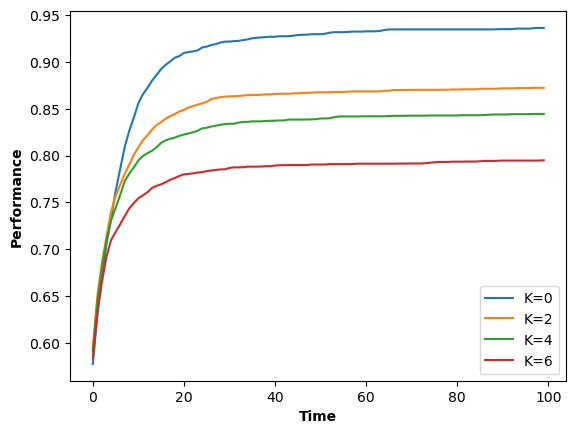

In [6]:
t0 = time.time()
np.random.seed(100)
gap_list = []
ress = []

N = 8
agent_num = 100
search_iteration = 100
landscape_repeat = 5
K_list = [0, 2, 4, 6]
performance_across_para = []
for K in K_list:  # key parameter for complexity
    performance_one_para = []
    agents_performance = []
    for i in range(landscape_repeat):  # landscape repetitions
        landscape = Landscape(N, K, None, None)
        landscape.initialize(norm=True)
        crowd = []
        for _ in range(agent_num):
            agent = Agent(N, landscape)
            crowd.append(agent)
        for agent in crowd:  # agent repetitions
            agent_performance = []
            for _ in range(search_iteration):
                agent.search()
                agent_performance.append(agent.fitness)
            agents_performance.append(agent_performance)

    for period in range(search_iteration):
        temp = [agent_performance[period] for agent_performance in agents_performance]
        performance_one_para.append(sum(temp) / len(temp))
    performance_across_para.append(performance_one_para)

x = range(search_iteration)
for index, K in enumerate(K_list):
    plt.plot(x, performance_across_para[index], label="K={0}".format(K))
plt.xlabel('Time', fontweight='bold', fontsize=10)
plt.ylabel('Performance', fontweight='bold', fontsize=10)
# plt.xticks(x)
plt.legend()
# plt.savefig("\Performance_across_K.png", transparent=False, dpi=200)
t1 = time.time()
print(time.strftime("%H:%M:%S", time.gmtime(t1-t0)))

In [7]:
t0 = time.time()
np.random.seed(100)
gap_list = []
ress = []

N = 8
agent_num = 100
search_iteration = 100
landscape_repeat = 5
K_list = [0, 2, 4, 6]
performance_across_para = []
for K in K_list:  # key parameter for complexity
    performance_one_para = []
    agents_performance = []
    for i in range(landscape_repeat):  # landscape repetitions
        landscape = Landscape(N, K, None, None)
        landscape.initialize(norm=True)
        crowd = []
        for _ in range(agent_num):
            agent = Agent(N, landscape)
            crowd.append(agent)
        for agent in crowd:  # agent repetitions
            agent_performance = []
            for _ in range(search_iteration):
                agent.search()
                agent_performance.append(agent.fitness)
            agents_performance.append(agent_performance)

    for period in range(search_iteration):
        temp = [agent_performance[period] for agent_performance in agents_performance]
        performance_one_para.append(sum(temp) / len(temp))
    performance_across_para.append(performance_one_para)

x = range(search_iteration)
for index, K in enumerate(K_list):
    plt.plot(x, performance_across_para[index], label="K={0}".format(K))
plt.xlabel('Time', fontweight='bold', fontsize=10)
plt.ylabel('Performance', fontweight='bold', fontsize=10)
# plt.xticks(x)
plt.legend()
# plt.savefig("\Performance_across_K.png", transparent=False, dpi=200)
t1 = time.time()
print(time.strftime("%H:%M:%S", time.gmtime(t1-t0)))

[0.5773445165363367, 0.629319559121318, 0.6710871037301853, 0.7049515086605894, 0.7328405475938033, 0.7619147577502511, 0.7855607056566986, 0.8091502506162391, 0.8264312399267816, 0.8404707330043999, 0.8559734652034908, 0.8655687441484708, 0.872341228061367, 0.8800613361335536, 0.8861432855652681, 0.8925210506373302, 0.8969623176201006, 0.9006066876089666, 0.9045202221646849, 0.906315992630326, 0.9096608637703703, 0.9105629193716336, 0.911321181394457, 0.9123469787121119, 0.9155405824605949, 0.9163932400009096, 0.9180963759635151, 0.9191324909948562, 0.9207613887376148, 0.9217310529969432, 0.9217627209830713, 0.9222781815569222, 0.9225644636590248, 0.9233716943456609, 0.9241255205864662, 0.9253457384310313, 0.9258666870155648, 0.9262425148490614, 0.9267078636782216, 0.9269442337087497, 0.9269801044048142, 0.9275010529893476, 0.9275010529893476, 0.9275706853957991, 0.9280916339803326, 0.9287606769807419, 0.9290615981030294, 0.9291680656722551, 0.929706473714365, 0.929706473714365, 0.929